In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from statsbombpy import sb
from mplsoccer.pitch import VerticalPitch
from matplotlib.colors import LinearSegmentedColormap

In [3]:
print("hola")

hola


Credentials

In [4]:
#Credentials
email = "itam_hackathon@hudl.com"
password = "pGwIprel"

# Team and Colors
team = "América"
team_color = '#DA291C'

comp_id = 73
season_id = 281

path_eff = [path_effects.Stroke(linewidth=2.5, foreground='white'), path_effects.Normal()]

# Custom colormap
colors = ["white", team_color]
n_bins = 100 # Discretizes the interpolation into bins
cmap_name = "team_color_map"
team_cmap = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

Get events from statsbomb

In [5]:
# Fetch matches
matches = sb.matches(competition_id=comp_id, season_id=season_id, creds={"user": email, "passwd": password})
matches = matches[(matches['home_team'] == team) | (matches['away_team'] == team)]
matches = matches[matches["match_status"] == "available"]
list_matches = matches['match_id'].tolist()

# Fetch event data
events = []
for n in list_matches:
   match_events = sb.events(match_id = n,creds={"user": email, "passwd": password})
   events.append(match_events)
events=pd.concat(events)

events[['x', 'y','z']] = events['location'].apply(pd.Series)
events[['pass_end_x', 'pass_end_y']] =events['pass_end_location'].apply(pd.Series)

/Users/omaratriano/Documents/TecNM/Local Segundo Semestre/Pawgrammers/back/goalsBack/.venv/lib/python3.12/site-packages/statsbombpy/sb.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  events = pd.concat([*events.values()], axis=0, ignore_index=True, sort=True)
/Users/omaratriano/Documents/TecNM/Local Segundo Semestre/Pawgrammers/back/goalsBack/.venv/lib/python3.12/site-packages/statsbombpy/sb.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  events = pd.concat([*events.values()], axis=0

Prepare the data

In [6]:
# Ensure that related_events is interpreted as a list, if needed
events['related_events'] = events['related_events'].apply(lambda x: eval(x) if isinstance(x, str) else x)
events['related_events']

0                                          NaN
1                                          NaN
2       [06ae509b-4010-5a44-a615-ada6dfa188c3]
3       [2336ee6e-99ff-5436-83bb-06314baeed07]
4       [fc1d45ed-71a1-5dc6-8308-c30f695f5ff6]
                         ...                  
3533                                       NaN
3534                                       NaN
3535                                       NaN
3536                                       NaN
3537                                       NaN
Name: related_events, Length: 165970, dtype: object

In [7]:
# Filter incomplete passes
incomplete_passes = events[(events['type'] == 'Pass') & (events['pass_outcome'] == 'Incomplete')]

In [24]:
#obtiene los corners realizados
corners = events[events["play_pattern"] == "From Corner"]
corners

,50_50,ball_receipt_outcome,ball_recovery_recovery_failure,block_deflection,block_save_block,carry_end_location,clearance_aerial_won,clearance_body_part,clearance_head,clearance_left_foot,...,goalkeeper_shot_saved_to_post,player_off_permanent,shot_redirect,shot_shot_goal_assist,x,y,z,pass_end_x,pass_end_y,related_player
52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,120.0,0.1,NaN,103.4,12.0,None
53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,104.4,11.0,NaN,96.5,19.0,None
54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,96.3,20.8,NaN,109.1,52.6,None
55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,76.5,28.1,NaN,76.9,17.1,None
56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,96.5,26.1,NaN,108.3,35.8,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3491,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,58.8,6.3,NaN,NaN,NaN,None
3529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [9]:
# Initialize a new column for the opposition player who intercepts or recovers the pass
events['related_player'] = None

/var/folders/cc/rlwx95ls5cd0lpjds5f8_f400000gn/T/ipykernel_20504/2674556058.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  events['related_player'] = None


In [25]:
# Create a dictionary for quick lookup of events by their id
event_dict = events.set_index('id').to_dict('index')

Tipos de eventos relacionados:<br/>
['50/50', 'Ball Receipt*', 'Ball Recovery', 'Block', 'Carry', 'Clearance', 'Dispossessed', 'Dribble', 'Dribbled Past', 'Duel', 'Error', 'Foul Committed', 'Foul Won', 'Goal Keeper', 'Half End', 'Half Start', 'Injury Stoppage', 'Interception', 'Miscontrol', 'Pass', 'Player Off', 'Player On', 'Pressure', 'Shield', 'Shot']

In [28]:
# Define the list of related event types to check
related_event_types = ['Goal']

In [29]:
# Define the event types that are relevant for checking aerial duel wins
aerial_duel_event_types = ['Pass', 'Clearance', 'Miscontrol']

In [42]:
for index, corner in corners.iterrows():
   if pd.notna(corner['shot_outcome']):
         print(corner['shot_outcome'])

Blocked
Off T
Off T
Goal
Wayward
Wayward
Blocked
Off T
Off T
Off T
Off T
Off T
Off T
Post
Off T
Off T
Off T
Off T
Blocked
Goal
Off T
Goal
Off T
Off T
Blocked
Saved
Off T
Off T
Off T
Off T
Blocked
Saved
Wayward
Off T
Off T
Saved
Off T
Saved
Off T
Blocked
Blocked
Wayward
Blocked
Off T
Off T
Saved
Saved
Off T
Off T
Wayward
Goal
Off T
Saved
Off T
Off T
Wayward
Post
Wayward
Saved
Goal
Blocked
Wayward
Off T
Blocked
Blocked
Off T
Off T
Wayward
Off T
Off T
Wayward
Off T
Saved
Saved
Blocked
Off T
Off T
Wayward
Saved
Wayward
Off T
Post
Blocked
Off T
Off T
Wayward
Off T
Wayward
Blocked
Blocked
Off T
Goal
Saved
Goal
Wayward
Blocked
Post
Off T
Saved
Off T
Off T
Wayward
Blocked
Wayward
Saved
Off T
Off T
Blocked
Blocked
Blocked
Blocked
Wayward
Saved
Blocked
Off T
Off T
Off T
Blocked
Off T
Blocked
Saved
Saved
Wayward
Saved
Goal
Off T
Saved
Off T
Wayward
Off T
Off T
Blocked
Blocked
Off T
Off T
Wayward
Off T
Goal
Blocked
Blocked
Blocked
Blocked
Off T
Off T
Wayward
Wayward
Blocked
Wayward
Saved
Off T
Sav

In [31]:
# Iterate over each incomplete pass to find the corresponding related event for first contact
for index, pass_event in corners.iterrows():
   related_event_ids = pass_event['related_events']

# Iterate over related events to find an event of interest for first contact
   for event_id in related_event_ids:
      if event_id in event_dict:
         related_event = event_dict[event_id]
         if related_event['type'] in related_event_types:
            related_player = related_event['player']
            events.loc[events['id'] == pass_event['id'], 'related_player'] = related_player
            break

TypeError: 'float' object is not iterable

In [14]:
df=events[(events['team']!=team)]
df=df[(df['pass_type']=="Corner")]

conditions=[df['pass_outcome'].isna(),df['pass_outcome'].notna() ]
values=[0,1]
df['success']=np.select(conditions, values)

left=df[(df['y']<=40) & (df['x']>=60)]
right=df[(df['y']>=40)& (df['x']>=60)]

/var/folders/cc/rlwx95ls5cd0lpjds5f8_f400000gn/T/ipykernel_20504/3822658711.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['success']=np.select(conditions, values)


In [19]:
df

,50_50,ball_receipt_outcome,ball_recovery_recovery_failure,block_deflection,block_save_block,carry_end_location,clearance_aerial_won,clearance_body_part,clearance_head,clearance_left_foot,...,player_off_permanent,shot_redirect,shot_shot_goal_assist,x,y,z,pass_end_x,pass_end_y,related_player,success
453,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,80.0,NaN,113.2,40.3,None,1
466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,0.1,NaN,107.9,47.4,None,0
805,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,0.1,NaN,110.0,46.4,None,0
369,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,0.1,NaN,115.2,32.3,None,0
370,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,80.0,NaN,111.3,32.3,None,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,80.0,NaN,114.9,45.2,None,0
849,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,0.1,NaN,111.2,40.3,None,1
643,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,80.0,NaN,112.3,78.0,None,0
242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,120.0,80.0,NaN,113.8,41.2,None,1


In [17]:
pitch = VerticalPitch(half=True, pitch_type='statsbomb',
                      pad_left=-15,
                      pad_right=-15,
                      pad_bottom=-37,
                      line_zorder=5
                      )
# Plotting functions
def plot_corners(data,ax,cmap=team_cmap):

   pitch.draw(ax=ax)

   data=data[(data["pass_end_y"]>18)&(data["pass_end_y"]<62)]

   bin_statistic = pitch.bin_statistic(data.pass_end_x, data.pass_end_y, values=data.success,statistic='mean', bins=(20, 13))
   bin_statistic['statistic'] = np.select([bin_statistic['statistic'] == 0], [0.001], bin_statistic['statistic'])
   bin_statistic['statistic'] = np.nan_to_num(bin_statistic['statistic'])
   bin_statistic2 = pitch.bin_statistic(data.pass_end_x, data.pass_end_y,statistic='count', bins=(20,13))
   pitch.heatmap(bin_statistic, ax=ax, cmap=cmap,edgecolor='lightgrey',alpha=0.75)

   pitch.label_heatmap(bin_statistic, color='black', fontsize=26,
      ax=ax, ha='center', va='bottom',fontweight="bold",
      str_format='{:.0%}'
      ,exclude_zeros=True
      ,path_effects=path_eff)

   pitch.label_heatmap(bin_statistic2, color='black', fontsize=18,
      ax=ax, ha='center', va='top',fontweight="bold",
      str_format='({:0.0f})',exclude_zeros=True, path_effects=path_eff)

   ax.set_title(f"Corners ({len(data)})")


def bar_chart(data, ax, color=team_color):
   grouped = data.groupby('related_player').size().reset_index(name='first_contact')
   grouped = grouped[grouped['first_contact'] > 1].sort_values('first_contact', ascending=True)
   bars = grouped['related_player']
   h = grouped['first_contact']
   y_pos = np.arange(len(bars))
   ax.barh(y_pos, h, color=color, lw=5, edgecolor='black')
   ax.set_yticks(y_pos)
   ax.set_yticklabels(bars, color="black", size=20)
   ax.tick_params(bottom=False, top=False, labelbottom=False)
   for side in ["right", "left", "top", "bottom"]:
      ax.spines[side].set_visible(False)
   for i, v in enumerate(h):      ax.text(v - 0.5, i - 0.1, f"{round(v, 3)}", color="white", fontsize=26, ha='center', fontweight="bold")



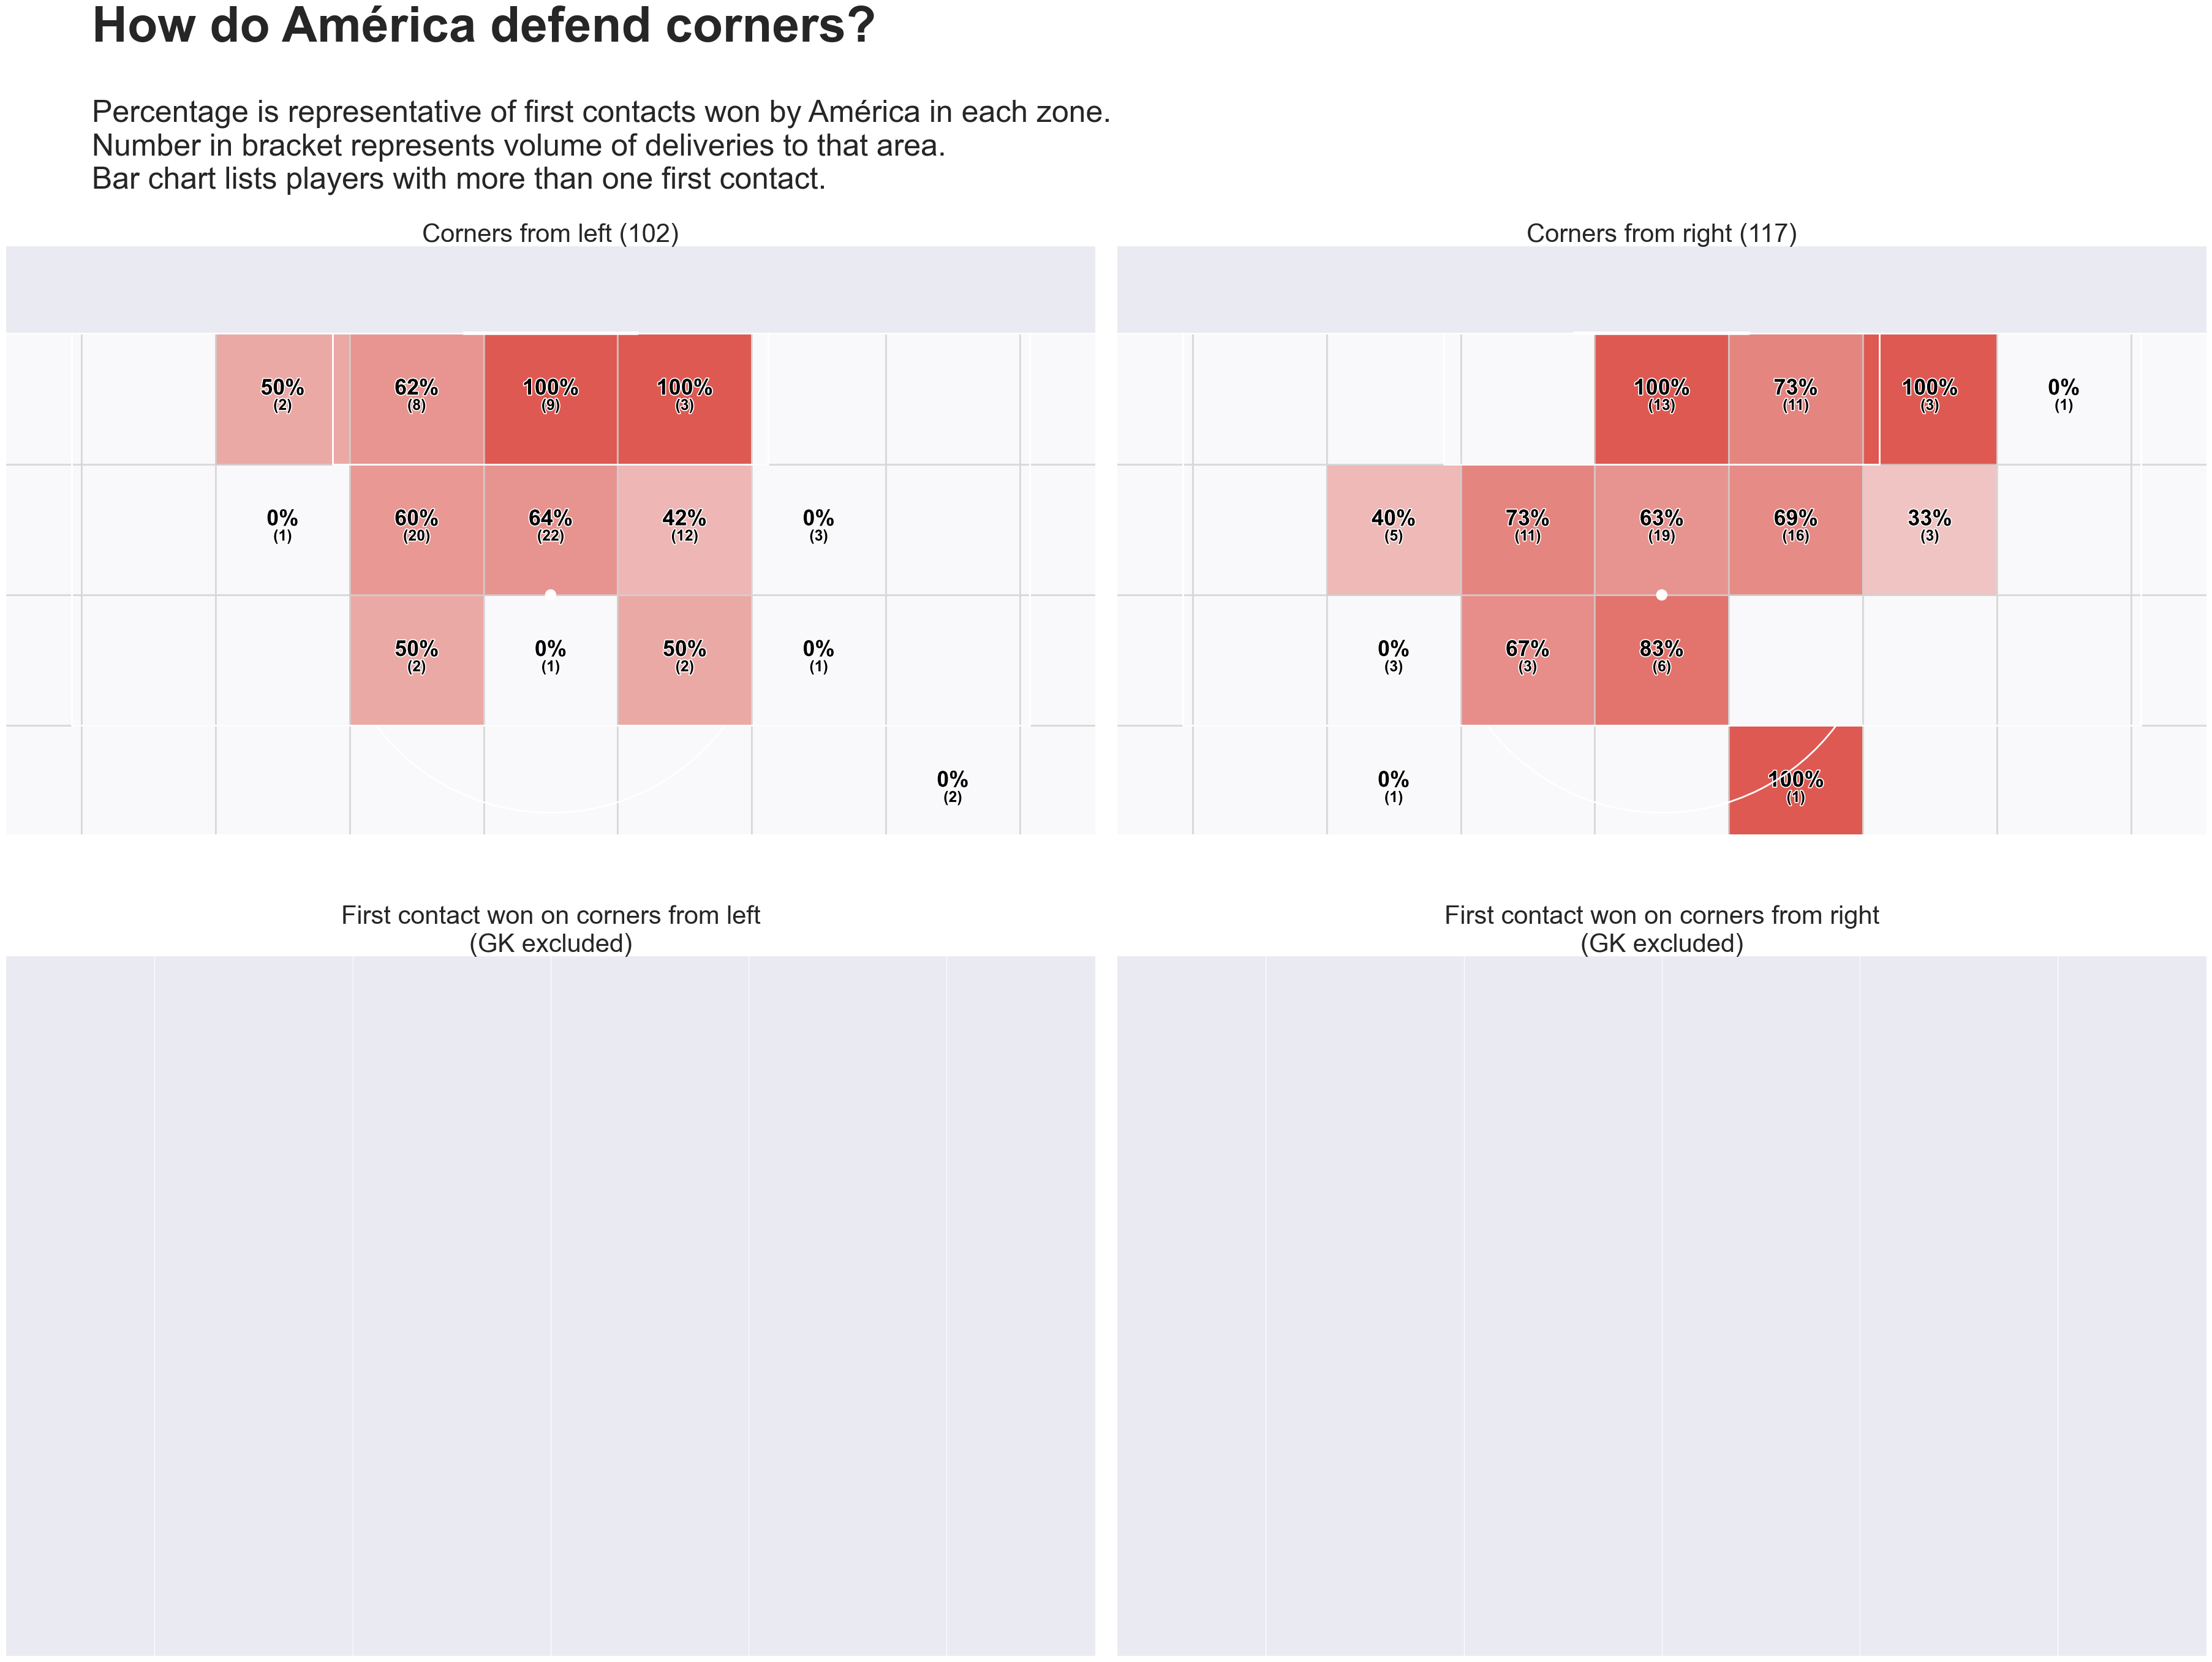

In [18]:
# Create plots
fig, axs = plt.subplots(2, 2, figsize=(36, 24), constrained_layout=True)

# Plot corners
plot_corners(left, axs[0, 0])
axs[0, 0].set_title(f"Corners from left ({len(left)})", size=30)

plot_corners(right, axs[0, 1])
axs[0, 1].set_title(f"Corners from right ({len(right)})", size=30)

# Plot bar charts
bar_chart(left, axs[1, 0])
axs[1, 0].set_title("First contact won on corners from left\n(GK excluded)", size=30)

bar_chart(right, axs[1, 1])
axs[1, 1].set_title("First contact won on corners from right\n(GK excluded)", size=30)

# Add main titles
fig.text(0.04, 1.1, f"How do {team} defend corners?", fontsize=58, fontweight='bold')
fig.text(0.04, 1.0, f"Percentage is representative of first contacts won by {team} in each zone.\n"
                    f"Number in bracket represents volume of deliveries to that area.\n"
                    f"Bar chart lists players with more than one first contact.", fontsize=36)

plt.show()